PHASE 1 IMPLEMENTATION TASKS:
Understanding video and extracting frames

In [1]:
print("okay")

okay


In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [3]:
# let's load the video file 
video_path="test_video.mp4"
"""
cv2.VideoCapture() is an OpenCV function that opens a video source.

That source could be:
- A video file.
- A webcam.
- A live camera stream.
"""
cap=cv2.VideoCapture(video_path)
if not cap.isOpened():
    print("Error: Could not open video.")
    exit()
else:
    print("Video opened successfully.")


Video opened successfully.


Extract video information

In [4]:
fps=cap.get(cv2.CAP_PROP_FPS)
frame_count=int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
width=int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height=int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
duration=frame_count/fps

print("FPS:", fps)
print("Total frames:", frame_count)
print("Width:", width)
print("Height:", height)
print("Duration:", duration, "seconds")

FPS: 30.00398549180718
Total frames: 266
Width: 720
Height: 1280
Duration: 8.865488888888889 seconds


Extract our first frame

In [5]:
success, frame = cap.read()

if success:
    print("Frame extracted successfully!")
    print("Frame shape:", frame.shape)
else:
    print("Could not extract frame")

Frame extracted successfully!
Frame shape: (1280, 720, 3)


Display the extracted frame

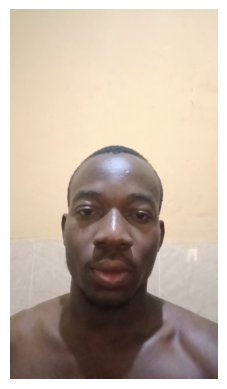

In [6]:
frame_rgb = cv2.cvtColor(
    frame,
    cv2.COLOR_BGR2RGB
)

plt.imshow(frame_rgb)
plt.axis("off")
plt.show()

Extract multiple frames

In [7]:
frames = []

cap.set(cv2.CAP_PROP_POS_FRAMES, 0)

for i in range(10):

    success, frame = cap.read()

    if success:
        frames.append(frame)

print("Frames extracted:", len(frames))

Frames extracted: 10


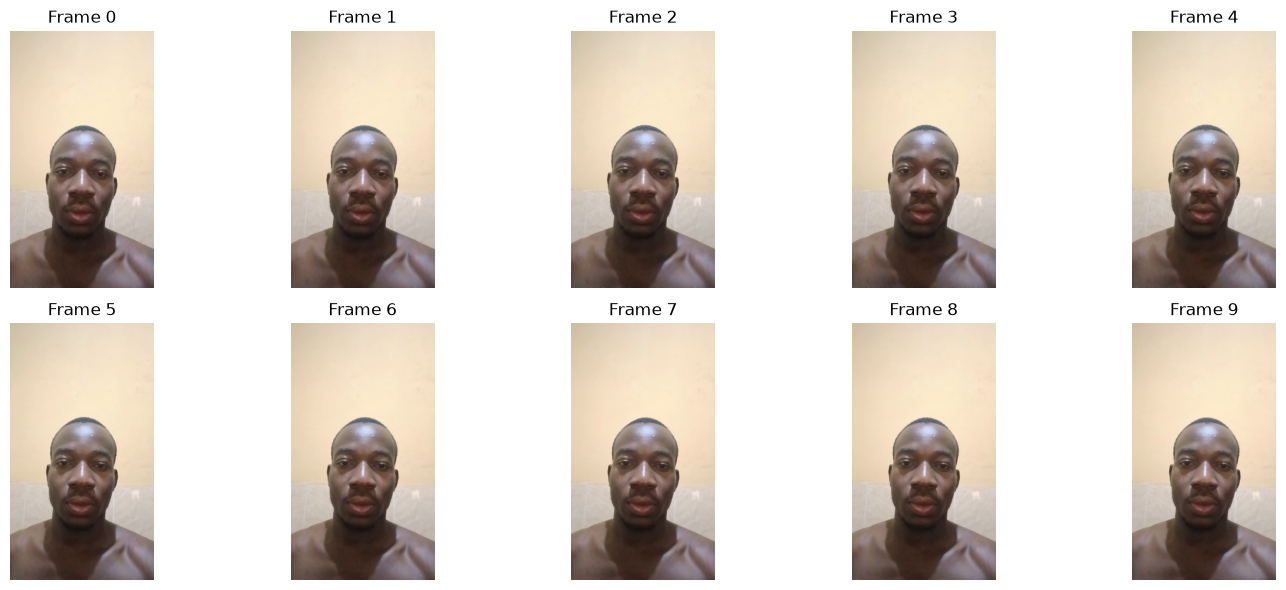

In [8]:
fig, axes = plt.subplots(2, 5, figsize=(15, 6))

for i, ax in enumerate(axes.flat):

    frame_rgb = cv2.cvtColor(
        frames[i],
        cv2.COLOR_BGR2RGB
    )

    ax.imshow(frame_rgb)
    ax.set_title(f"Frame {i}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [11]:
# let's read from 50th frame to 60th frame
frames=[]
cap.set(cv2.CAP_PROP_POS_FRAMES, 120)
for i in range(10):
    success, frame = cap.read()

    if success:
        frames.append(frame)
print("Frames extracted:", len(frames))

Frames extracted: 10


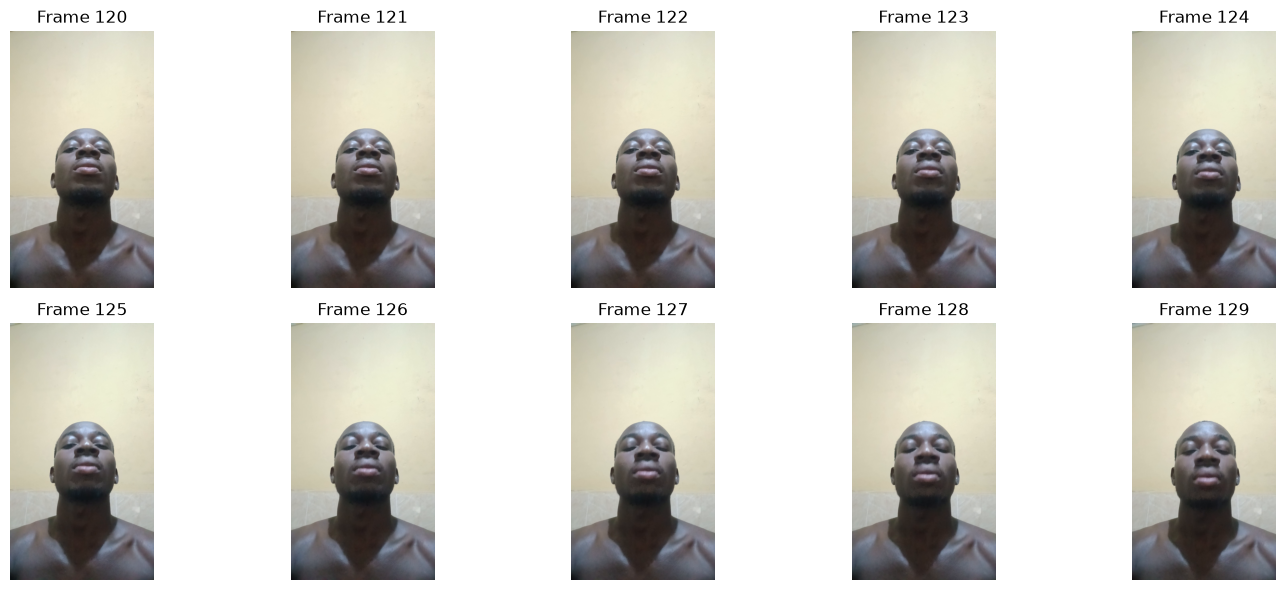

In [13]:
# let's plot the frames from 50th to 60th frame
fig, axes = plt.subplots(2, 5, figsize=(15, 6))

for i, ax in enumerate(axes.flat):

    frame_rgb = cv2.cvtColor(
        frames[i],
        cv2.COLOR_BGR2RGB
    )

    ax.imshow(frame_rgb)
    ax.set_title(f"Frame {120+i}")
    ax.axis("off")

plt.tight_layout()
plt.show()

PHASE 2 IMPLEMENTATION :
Frame Sampling and Image Processing

Strategy A — Extract every frame

In [14]:
all_frames = []

cap.set(cv2.CAP_PROP_POS_FRAMES, 0)

while True:

    success, frame = cap.read()

    if not success:
        break

    all_frames.append(frame)

print("Total extracted frames:", len(all_frames))

Total extracted frames: 266


Strategy B — Extract every Nth frame

In [15]:
sampled_frames = []

cap.set(cv2.CAP_PROP_POS_FRAMES, 0)

frame_interval = 10
frame_number = 0

while True:

    success, frame = cap.read()

    if not success:
        break

    if frame_number % frame_interval == 0:
        sampled_frames.append(frame)

    frame_number += 1

print("Original frames:", len(all_frames))
print("Sampled frames:", len(sampled_frames))

Original frames: 266
Sampled frames: 27


Strategy C — Time-based sampling

In [17]:
sampled_frames = []

cap.set(cv2.CAP_PROP_POS_FRAMES, 0)

seconds_interval = 1

frame_interval = int(fps * seconds_interval)

frame_number = 0

while True:

    success, frame = cap.read()

    if not success:
        break

    if frame_number % frame_interval == 0:

        sampled_frames.append({
            "frame_number": frame_number,
            "timestamp": frame_number / fps,
            "image": frame
        })

    frame_number += 1

print("Sampled frames:", len(sampled_frames))
print("Sampled frame details:")
for frame_info in sampled_frames:
    print(f"Frame Number: {frame_info['frame_number']}, Timestamp: {frame_info['timestamp']:.2f} seconds")

Sampled frames: 9
Sampled frame details:
Frame Number: 0, Timestamp: 0.00 seconds
Frame Number: 30, Timestamp: 1.00 seconds
Frame Number: 60, Timestamp: 2.00 seconds
Frame Number: 90, Timestamp: 3.00 seconds
Frame Number: 120, Timestamp: 4.00 seconds
Frame Number: 150, Timestamp: 5.00 seconds
Frame Number: 180, Timestamp: 6.00 seconds
Frame Number: 210, Timestamp: 7.00 seconds
Frame Number: 240, Timestamp: 8.00 seconds


Understanding image resolution
Note reducing image resolution give less processing cost but reduces quality of processed image


In [18]:
# Step 1: Resize a frame
frame = all_frames[0]

original_height, original_width = frame.shape[:2]

resized_frame = cv2.resize(
    frame,
    (640, 360)
)

print("Original:", frame.shape)
print("Resized:", resized_frame.shape)

Original: (1280, 720, 3)
Resized: (360, 640, 3)


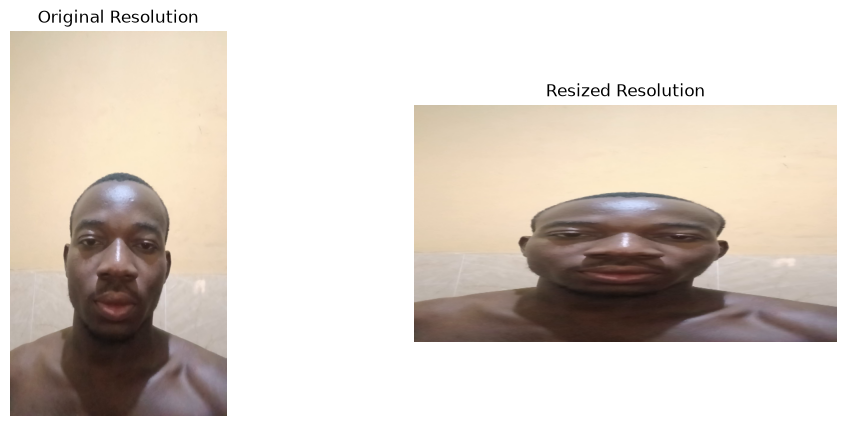

In [19]:
# Step 2: Compare both images
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

original_rgb = cv2.cvtColor(
    frame,
    cv2.COLOR_BGR2RGB
)

resized_rgb = cv2.cvtColor(
    resized_frame,
    cv2.COLOR_BGR2RGB
)

axes[0].imshow(original_rgb)
axes[0].set_title("Original Resolution")

axes[1].imshow(resized_rgb)
axes[1].set_title("Resized Resolution")

for ax in axes:
    ax.axis("off")

plt.show()